In [21]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

MU = 10.0
T_FINAL = 40.0

X0 = 1.0
V0 = 0.0
N_EVAL = 3000

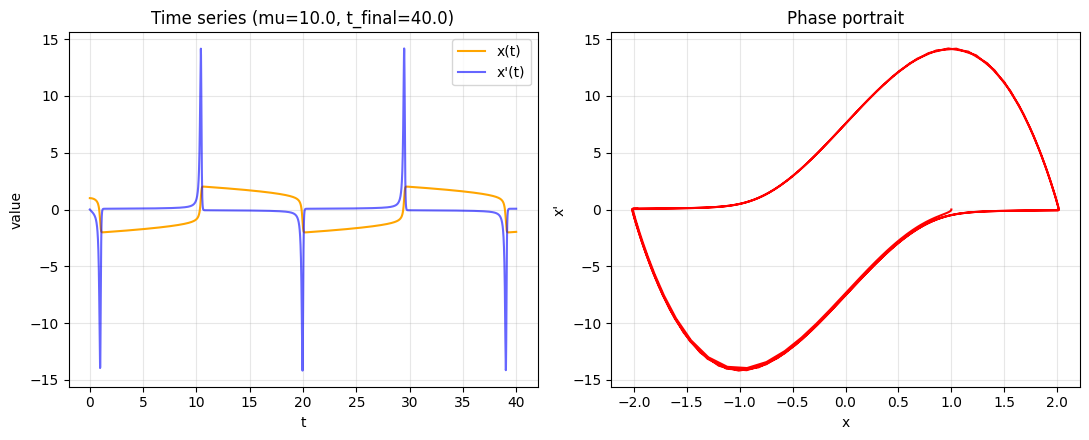

In [23]:
def van_der_pol_rhs(t, y, mu):
    x, v = y
    return [v, mu * (1 - x ** 2) * v - x]


t_eval = np.linspace(0, T_FINAL, N_EVAL)
sol = solve_ivp(
    van_der_pol_rhs, [0, T_FINAL], [X0, V0],
    t_eval=t_eval, args=(MU,),
    method="RK45", rtol=1e-9, atol=1e-9,
)
t, x, v = sol.t, sol.y[0], sol.y[1]

fig, (ax_time, ax_phase) = plt.subplots(1, 2, figsize=(11, 4.5))

ax_time.plot(t, x, color="orange", label="x(t)")
ax_time.plot(t, v, color="blue", alpha=0.6, label="x'(t)")
ax_time.set_xlabel("t")
ax_time.set_ylabel("value")
ax_time.set_title(f"Time series (mu={MU}, t_final={T_FINAL})")
ax_time.legend()
ax_time.grid(alpha=0.3)

ax_phase.plot(x, v, color="red")
ax_phase.set_xlabel("x")
ax_phase.set_ylabel("x'")
ax_phase.set_title("Phase portrait")
ax_phase.grid(alpha=0.3)

plt.tight_layout()
plt.show()